# Entregable 2: predicción del retraso en P18 desde P10

**Curso:** Aprendizaje de Máquina (1INF02), PUCP 2026-2.

Este notebook reúne todo el código del Entregable 2, en el mismo orden que el paper:

1. Preprocesamiento y tabla de calidad
2. Análisis exploratorio (solo el periodo de desarrollo)
3. Variables causales
4. Regresión: líneas base, Ridge, Random Forest y HistGradientBoosting; validación cruzada *forward-chaining* por días, búsqueda de hiperparámetros y evaluación en la prueba
5. Análisis complementarios: curva por punto de partida, sensibilidad del umbral e importancia por permutación
6. Análisis de la revisión: comparación por día, descomposición del error, sesgo de selección, línea base por hora y tipo de día, semillas

**Datos:** se necesita `Times.csv`. Se busca primero junto a este notebook y luego en `../Dataset/Times.csv`, la ubicación en el repositorio.
**Salidas:** se escriben en la carpeta `salidas/` (subcarpetas `data/`, `resultados/` y `figuras/`).
**Tiempo de ejecución:** unos 9 minutos con 4 núcleos.

**Sobre la prueba.** La evaluación única oficial se hizo con el protocolo congelado en el *commit* `6445b10` del repositorio. Este notebook usa el mismo código y las mismas semillas, así que **reproduce** esa evaluación y no toma decisiones nuevas con ella. La última celda comprueba que los resultados coinciden con los oficiales.

In [1]:
import datetime as dt
import json
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, loguniform, wilcoxon
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn

# Rutas
CARPETA = Path.cwd()
candidatos = [CARPETA / "Times.csv", CARPETA.parent / "Dataset" / "Times.csv"]
DATASET = next((c for c in candidatos if c.exists()), None)
assert DATASET is not None, "No se encontró Times.csv: colócalo junto al notebook o en ../Dataset/"
RAIZ = CARPETA / "salidas"          # todas las salidas van aquí
RES = RAIZ / "resultados"
FIG = RAIZ / "figuras"
for d in (RAIZ, RES, FIG, RAIZ / "data"):
    d.mkdir(parents=True, exist_ok=True)

print("Datos:", DATASET)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Datos: /home/user/1inf02-machine-learning-project/Dataset/Times.csv
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


## 0. Estilo de las figuras
Paleta categórica validada y formato de una columna IEEE.

In [2]:
# Paleta categórica validada (orden fijo; nunca se cicla).
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#d9d8d4"
ANCHO_COL = 3.5  # pulgadas

plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.edgecolor": TINTA2,
    "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": REJILLA, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.6, "legend.frameon": False, "savefig.bbox": "tight",
    "savefig.dpi": 300, "axes.formatter.use_locale": False,
})


def coma(ax, eje="y", decimales=0):
    """Separador decimal con coma en los ticks (convención en español)."""
    from matplotlib.ticker import FuncFormatter
    f = FuncFormatter(lambda v, _: f"{v:.{decimales}f}".replace(".", ","))
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)


## 1. Preprocesamiento

Convierte los arreglos de 18 puntos de control en columnas y recalcula el retraso en minutos, con segundos, como hora real menos hora programada. Luego aplica las reglas de limpieza, que se fijaron antes de modelar:
- **R1.** Horario programado no creciente: se excluye la vuelta.
- **R2.** Paso con hora incompatible, $|d| > 60$ min: se marca como NaN.
- **R3.** Tramo con tiempo negativo: se excluye la vuelta.
- **R4.** Salto mayor a 15 min entre puntos consecutivos: solo se marca.

Las aserciones verifican la estructura de los datos de entrada y de salida.

In [3]:
N_PUNTOS = 18
SALTO_MIN = 15  # salto entre puntos consecutivos que se marca (no se elimina)


def a_minutos(hhmmss: str) -> float:
    h, m, s = (int(x) for x in hhmmss.split(":"))
    return h * 60 + m + s / 60


def separar(arreglo: str) -> list[str]:
    return arreglo.strip("{}").split(",")


def preprocesar(umbral: float, salida: str = "data/vueltas_limpias.csv",
         tabla: str = "resultados/calidad.csv") -> None:
    T = pd.read_csv(DATASET, dtype={"vehicle_id_id": str})
    n_vueltas, n_celdas = len(T), len(T) * N_PUNTOS

    prog = T.start_time.map(separar)
    real = T.end_time.map(separar)
    dif = T.difference_time.map(separar)
    assert (prog.map(len) == N_PUNTOS).all() and (real.map(len) == N_PUNTOS).all() \
        and (dif.map(len) == N_PUNTOS).all(), "algún arreglo no tiene 18 valores"
    assert not T.duplicated(["vehicle_id_id", "date", "lap"]).any(), "vuelta duplicada"

    S = pd.DataFrame([[a_minutos(x) for x in fila] for fila in prog])
    E = pd.DataFrame([[np.nan if x == "00:00:00" else a_minutos(x) for x in fila] for fila in real])
    Dorig = pd.DataFrame([[np.nan if x == "-" else float(x) for x in fila] for fila in dif])
    # Los pasos no registrados aparecen igual en ambas columnas ("-" y 00:00:00).
    assert (E.isna() == Dorig.isna()).all().all(), "faltantes de end_time y difference_time no coinciden"

    D = E - S  # retraso en minutos con segundos; positivo = tarde
    # difference_time es la parte entera de D: se verifica en vez de suponerlo.
    obs = Dorig.notna()
    coincide = (np.trunc(D[obs]) == Dorig[obs]).sum().sum() / obs.sum().sum()

    filas = []

    def registrar(regla, unidad, n, total, tratamiento):
        filas.append(dict(regla=regla, unidad=unidad, afectados=int(n), total=int(total),
                          porcentaje=round(100 * n / total, 2), tratamiento=tratamiento))

    registrar("Paso no registrado ('-' / 00:00:00)", "celda", E.isna().sum().sum(), n_celdas,
              "NaN + indicador; nunca se imputa el objetivo")

    # R1. Horario programado no creciente: arreglo corrupto -> excluir vuelta.
    r1 = ~(S.diff(axis=1).iloc[:, 1:] >= 0).all(axis=1)
    registrar("Horario programado no creciente", "vuelta", r1.sum(), n_vueltas, "excluir vuelta")

    # R2. Paso con hora incompatible con su vuelta (|retraso| > umbral) -> NaN en esa celda.
    #     122 de 141 negativos tienen hora de reloj 4-6 h en vueltas que salen 16-20 h.
    r2 = (D.abs() > umbral) & ~r1.values[:, None]
    registrar(f"Paso con hora incompatible (|d| > {umbral:g} min)", "celda", r2.sum().sum(),
              n_celdas, "marcar como NaN")
    # Tramos negativos antes de aplicar R2 (para documentar que R2 los explica).
    neg_antes = ((E.ffill(axis=1).diff(axis=1).iloc[:, 1:] < 0).any(axis=1) & ~r1).sum()
    D, E = D.mask(r2), E.mask(r2)

    # R3. Tiempo de tramo negativo (entre pasos observados) -> excluir vuelta.
    tramo = E.ffill(axis=1).diff(axis=1).iloc[:, 1:]
    r3 = (tramo < 0).any(axis=1) & ~r1
    registrar(f"Tiempo de tramo negativo (antes de R2: {neg_antes} vueltas)", "vuelta", r3.sum(),
              n_vueltas, "excluir vuelta")

    # R4. Salto de retraso > 15 min entre puntos observados consecutivos -> solo se marca.
    salto = D.ffill(axis=1).diff(axis=1).abs().iloc[:, 1:]
    r4 = (salto > SALTO_MIN).any(axis=1) & ~r1 & ~r3
    registrar(f"Salto de retraso > {SALTO_MIN} min", "vuelta", r4.sum(), n_vueltas,
              "conservar con indicador")

    conservar = ~r1 & ~r3
    out = pd.DataFrame({
        "id": T.id, "fecha": T.date, "vuelta": T.lap, "vehiculo": T.vehicle_id_id,
        "salto_grande": r4.astype(int),
    })
    for k in range(N_PUNTOS):
        out[f"s{k + 1}"] = S[k].round(4)
    for k in range(N_PUNTOS):
        out[f"d{k + 1}"] = D[k].round(4)
    out = out[conservar].sort_values(["vehiculo", "fecha", "vuelta"]).reset_index(drop=True)

    registrar("Vueltas conservadas", "vuelta", len(out), n_vueltas, "-")
    registrar("Vueltas conservadas con P18 observado", "vuelta", out.d18.notna().sum(), n_vueltas,
              "muestra para predecir P18")

    # Invariantes de la salida.
    assert out.id.is_unique
    assert (out[[f"s{k + 1}" for k in range(N_PUNTOS)]].diff(axis=1).iloc[:, 1:] >= 0).all().all()
    assert (out[[f"d{k + 1}" for k in range(N_PUNTOS)]].abs().max() <= umbral).all()

    (RAIZ / "data").mkdir(exist_ok=True)
    (RAIZ / "resultados").mkdir(exist_ok=True)
    out.to_csv(RAIZ / salida, index=False)
    calidad = pd.DataFrame(filas)
    calidad.to_csv(RAIZ / tabla, index=False)

    print(f"difference_time == trunc(real - programada): {coincide:.4%} de las celdas observadas")
    print(calidad.to_string(index=False))


In [4]:
preprocesar(60.0)

difference_time == trunc(real - programada): 100.0000% de las celdas observadas
                                             regla unidad  afectados  total  porcentaje                                  tratamiento
               Paso no registrado ('-' / 00:00:00)  celda       7746  84726        9.14 NaN + indicador; nunca se imputa el objetivo
                   Horario programado no creciente vuelta        148   4707        3.14                               excluir vuelta
         Paso con hora incompatible (|d| > 60 min)  celda        156  84726        0.18                              marcar como NaN
Tiempo de tramo negativo (antes de R2: 30 vueltas) vuelta          0   4707        0.00                               excluir vuelta
                         Salto de retraso > 15 min vuelta         55   4707        1.17                      conservar con indicador
                               Vueltas conservadas vuelta       4559   4707       96.86                                   

## 2. Variables causales
Solo usan información disponible cuando el bus pasa por el punto $k$.

In [5]:
OBJETIVO = "d18"
CATEGORICAS = ["vehiculo", "dia_semana"]


def construir(df: pd.DataFrame, k: int, vuelta_anterior: bool = True) -> pd.DataFrame:
    d = df[[f"d{i}" for i in range(1, k + 1)]]
    X = d.copy()
    ultimo = d.ffill(axis=1).iloc[:, -1]
    X["ultimo_retraso"] = ultimo                      # retraso más reciente observado
    X["variacion"] = ultimo - d.ffill(axis=1).iloc[:, -2] if k > 1 else 0.0
    X["n_faltantes"] = d.isna().sum(axis=1)
    salida = df["s1"]                                 # hora programada de salida (min)
    X["hora_sin"] = np.sin(2 * np.pi * salida / 1440)
    X["hora_cos"] = np.cos(2 * np.pi * salida / 1440)
    X["plantilla"] = (df["s18"] - df["s1"]).round()   # duración programada: 147/161/168/170
    X["restante_prog"] = df["s18"] - df[f"s{k}"]
    X["vuelta"] = df["vuelta"]
    X["dia_semana"] = pd.to_datetime(df["fecha"]).dt.dayofweek
    X["vehiculo"] = df["vehiculo"].astype(int)
    if vuelta_anterior:
        X["retraso_vuelta_anterior"] = retraso_vuelta_anterior(df)
    return X


def retraso_vuelta_anterior(df: pd.DataFrame) -> pd.Series:
    """Retraso en P18 de la vuelta inmediatamente anterior del mismo bus y día.

    NaN si es la primera vuelta del día, si hay un hueco en la numeración
    (no sabemos si la vuelta no se hizo o no se registró) o si su P18 falta.
    """
    orden = df.sort_values(["vehiculo", "fecha", "vuelta"])
    g = orden.groupby(["vehiculo", "fecha"])
    previo = g[OBJETIVO].shift()
    consecutiva = g["vuelta"].diff() == 1
    return previo.where(consecutiva).reindex(df.index)


## 3. Análisis exploratorio
Solo usa el periodo de **desarrollo** (6–26 ene), para que ninguna figura que guíe decisiones mire la prueba.

In [6]:
FIN_DESARROLLO = "2025-01-26"
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]


def eda():
    FIG.mkdir(exist_ok=True)
    df = pd.read_csv(RAIZ / "data/vueltas_limpias.csv", dtype={"vehiculo": str})
    df = df[df.fecha <= FIN_DESARROLLO].copy()
    D = df[[f"d{i}" for i in range(1, 19)]]
    puntos = np.arange(1, 19)
    q = D.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).T
    faltante = 100 * D.isna().mean()

    # Figura 1: perfil del retraso por punto de control + % de pasos no registrados.
    fig, (a, b) = plt.subplots(2, 1, figsize=(ANCHO_COL, 3.3), sharex=True,
                               gridspec_kw={"height_ratios": [2.2, 1]})
    a.fill_between(puntos, q[0.1], q[0.9], color=AZUL, alpha=0.15, lw=0, label="p10–p90")
    a.fill_between(puntos, q[0.25], q[0.75], color=AZUL, alpha=0.35, lw=0, label="p25–p75")
    a.plot(puntos, q[0.5], color=AZUL, marker="o", ms=3, label="Mediana")
    a.axhline(0, color=TINTA2, lw=0.8)
    a.axvline(10, color=TINTA2, lw=0.8, ls="--")
    a.text(10.2, 11, "P10: punto\nde predicción", fontsize=6.5, color=TINTA2, va="top")
    a.set_ylabel("Retraso (min)")
    a.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
    a.yaxis.set_major_locator(plt.MultipleLocator(5))
    b.bar(puntos, faltante, color=AZUL, width=0.7)
    b.set_ylabel("No registrado (%)")
    b.set_xlabel("Punto de control")
    b.set_xticks(puntos, [f"{p}" for p in puntos])
    coma(b)
    fig.align_ylabels()
    fig.savefig(FIG / "eda_por_punto.pdf")
    plt.show()

    # Figura 2: retraso en P18 por hora de salida (según plantilla) y por día de la semana.
    y = df[df.d18.notna()].copy()
    y["hora"] = (y.s1 // 60).astype(int)
    y["plantilla"] = (y.s18 - y.s1).round().astype(int)
    y["dia"] = pd.to_datetime(y.fecha).dt.dayofweek
    fig, (a, b) = plt.subplots(1, 2, figsize=(ANCHO_COL * 2, 2.3),
                               gridspec_kw={"width_ratios": [1.6, 1]})
    # La plantilla de 168 min solo existe en la prueba (reemplaza a la de 170 desde el 27 ene).
    for plantilla, color in zip([161, 170, 147], [AZUL, NARANJA, AQUA]):
        s = y[y.plantilla == plantilla].groupby("hora").d18.agg(["median", "size"])
        s = s[s["size"] >= 10]  # se omiten horas con menos de 10 vueltas
        n = (y.plantilla == plantilla).sum()
        a.plot(s.index, s["median"], color=color, marker="o", ms=3,
               label=f"{plantilla} min (n = {n:,})".replace(",", " "))
    a.axhline(0, color=TINTA2, lw=0.8)
    a.set_xlabel("Hora programada de salida")
    a.set_ylabel("Retraso mediano en P18 (min)")
    a.legend(title="Plantilla (desarrollo)", title_fontsize=7, loc="upper left")
    a.set_xticks(range(4, 21, 2))
    grupos = [y.loc[y.dia == d, "d18"].to_numpy() for d in range(7)]
    bp = b.boxplot(grupos, widths=0.55, showfliers=False, patch_artist=True,
                   medianprops={"color": "white", "lw": 1.4},
                   whiskerprops={"color": TINTA2}, capprops={"color": TINTA2})
    for caja, d in zip(bp["boxes"], range(7)):
        caja.set(facecolor=NARANJA if d == 5 else AZUL, edgecolor="none")
    b.set_xticks(range(1, 8), [f"{DIAS[d]}\n{len(g)}" for d, g in enumerate(grupos)])
    b.axhline(0, color=TINTA2, lw=0.8)
    b.set_ylabel("Retraso en P18 (min)")
    b.set_xlabel("Día (debajo: n vueltas)")
    fig.tight_layout()
    fig.savefig(FIG / "eda_p18.pdf")
    plt.show()

    # Resumen numérico que respalda el texto del paper.
    resumen = pd.DataFrame({"punto": puntos, "p10": q[0.1].values, "p25": q[0.25].values,
                            "mediana": q[0.5].values, "p75": q[0.75].values, "p90": q[0.9].values,
                            "pct_no_registrado": faltante.values})
    resumen.round(2).to_csv(RAIZ / "resultados/eda_resumen.csv", index=False)
    por_dia = y.groupby("dia").d18.agg(["size", "median", "mean"]).rename(index=dict(enumerate(DIAS)))
    print(f"Desarrollo: {len(df)} vueltas, {len(y)} con P18\n", resumen.round(1).to_string(index=False))
    print(por_dia.round(1).to_string())


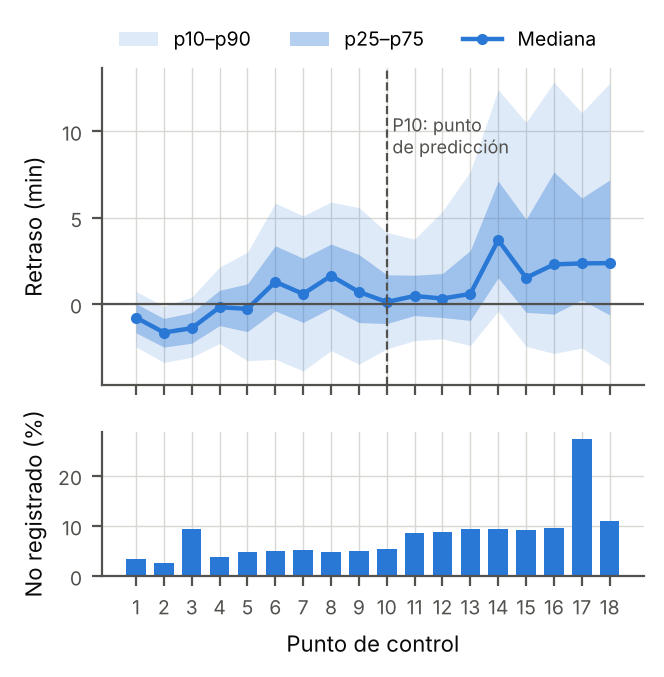

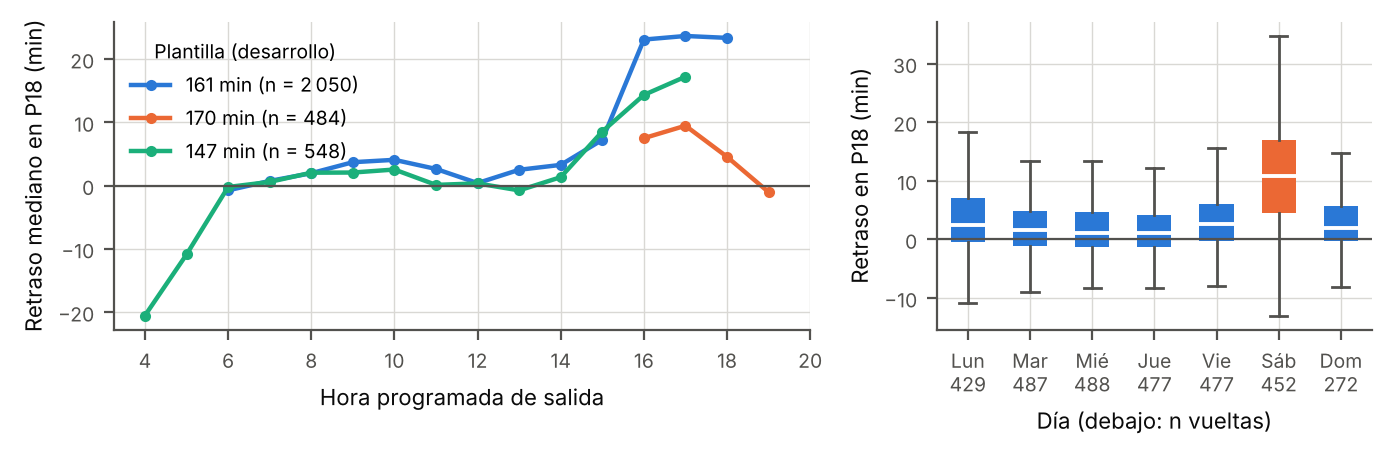

Desarrollo: 3465 vueltas, 3082 con P18
  punto  p10  p25  mediana  p75  p90  pct_no_registrado
     1 -2.5 -1.7     -0.8  0.0  0.7                3.4
     2 -3.4 -2.5     -1.6 -0.8 -0.1                2.6
     3 -3.1 -2.3     -1.4 -0.5  0.4                9.5
     4 -2.3 -1.2     -0.2  0.8  2.1                3.9
     5 -3.3 -1.6     -0.3  1.2  3.0                4.8
     6 -3.2 -0.4      1.3  3.4  5.8                5.0
     7 -3.9 -1.1      0.6  2.6  5.1                5.2
     8 -2.7 -0.2      1.6  3.5  5.9                4.7
     9 -3.5 -1.1      0.7  2.9  5.6                5.0
    10 -2.6 -1.1      0.1  1.7  4.1                5.5
    11 -2.1 -0.7      0.5  1.7  3.8                8.5
    12 -2.0 -0.8      0.3  1.8  5.4                8.8
    13 -2.4 -1.0      0.6  3.1  7.7                9.4
    14 -0.4  1.5      3.7  7.1 12.4                9.4
    15 -2.4 -0.5      1.5  4.9 10.5                9.2
    16 -2.9 -0.6      2.3  7.6 12.8                9.6
    17 -2.6  0.2      2.4

In [7]:
eda()

## 4. Regresión

Protocolo, fijado antes de ver la prueba:
- **Partición.** Desarrollo: 6–26 ene 2025. Prueba: 27 ene – 1 feb 2025.
- **Validación cruzada.** *Forward-chaining* por días: 11 días iniciales de entrenamiento y 5 pliegues de 2 días de validación.
- **Ablación.** La variable "retraso de la vuelta anterior" se incluye solo si mejora el MAE de validación cruzada en al menos 2 de los 3 modelos.
- **Hiperparámetros.** Búsqueda aleatoria con esa misma validación cruzada.
- **Prueba.** Cada modelo se reentrena con todo el desarrollo y se evalúa una vez.

El registro `PRUEBA_EVALUADA.txt` impide repetir la evaluación en la misma carpeta de salidas.

In [8]:
SEMILLA = 42
K = 10                      # punto de control desde el que se predice
FIN_DESARROLLO = "2025-01-26"
INICIO_PRUEBA = "2025-01-27"
N_ITER = 40                 # configuraciones por búsqueda aleatoria
N_BOOT = 2000               # remuestreos por día para los IC


# ---------------------------------------------------------------- líneas base
class RetrasoCero(BaseEstimator, RegressorMixin):
    """Supone que el bus llega exactamente a la hora programada."""
    def fit(self, X, y):
        return self

    def predict(self, X):
        return np.zeros(len(X))


class Persistencia(BaseEstimator, RegressorMixin):
    """El último retraso observado hasta k se mantiene hasta P18."""
    def fit(self, X, y):
        return self

    def predict(self, X):
        return X["ultimo_retraso"].fillna(0).to_numpy()


class MediaHistoricaHora(BaseEstimator, RegressorMixin):
    """Media del retraso en P18 por hora programada de salida (ajustada en entrenamiento)."""
    def fit(self, X, y):
        hora = self._hora(X)
        self.medias_ = pd.Series(np.asarray(y)).groupby(hora.to_numpy()).mean()
        self.global_ = float(np.mean(y))
        return self

    def predict(self, X):
        return self._hora(X).map(self.medias_).fillna(self.global_).to_numpy()

    @staticmethod
    def _hora(X):
        ang = np.arctan2(X["hora_sin"], X["hora_cos"]) % (2 * np.pi)
        return (ang / (2 * np.pi) * 24 + 1e-6).astype(int)


# ---------------------------------------------------------------- modelos
def modelos(columnas):
    numericas = [c for c in columnas if c not in CATEGORICAS]
    ridge = make_pipeline(
        ColumnTransformer([
            ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                  StandardScaler()), numericas),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
        ]),
        Ridge())
    rf = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                       RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEMILLA))
    hgb = HistGradientBoostingRegressor(categorical_features=CATEGORICAS, early_stopping=False,
                                        random_state=SEMILLA)
    espacios = {
        "Ridge": {"ridge__alpha": loguniform(1e-3, 1e3)},
        "Random Forest": {
            "randomforestregressor__max_depth": [None, 6, 10, 16],
            "randomforestregressor__min_samples_leaf": [1, 2, 5, 10, 20],
            "randomforestregressor__max_features": [0.3, 0.5, 0.8, 1.0],
        },
        "HistGradientBoosting": {
            "learning_rate": loguniform(0.01, 0.2),
            "max_iter": [100, 200, 400, 800],
            "max_leaf_nodes": [7, 15, 31, 63],
            "min_samples_leaf": [5, 10, 20, 40],
            "l2_regularization": loguniform(1e-3, 10),
        },
    }
    return {"Ridge": ridge, "Random Forest": rf, "HistGradientBoosting": hgb}, espacios


LINEAS_BASE = {"Retraso cero": RetrasoCero(), "Persistencia": Persistencia(),
               "Media histórica por hora": MediaHistoricaHora()}


# ---------------------------------------------------------------- utilidades
def pliegues_forward_chaining(fechas: pd.Series, n_inicial=11, tam=2):
    dias = np.sort(fechas.unique())
    assert len(dias) == n_inicial + 5 * tam, f"se esperaban 21 días de desarrollo, hay {len(dias)}"
    salida = []
    for i in range(n_inicial, len(dias), tam):
        tr = np.flatnonzero(fechas.isin(dias[:i]))
        va = np.flatnonzero(fechas.isin(dias[i:i + tam]))
        salida.append((tr, va))
    return salida


def metricas(y, p):
    e = np.abs(np.asarray(y) - np.asarray(p))
    return {"MAE": e.mean(), "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p),
            "pct_err_le_2": 100 * np.mean(e <= 2)}


def cv_por_pliegue(modelo, X, y, pliegues):
    filas = []
    for i, (tr, va) in enumerate(pliegues):
        m = clone(modelo).fit(X.iloc[tr], y.iloc[tr])
        filas.append({"pliegue": i + 1, **metricas(y.iloc[va], m.predict(X.iloc[va]))})
    return pd.DataFrame(filas)


def bootstrap_por_dia(y, p, fechas, rng):
    dias = fechas.unique()
    grupos = {d: np.flatnonzero(fechas.to_numpy() == d) for d in dias}
    muestras = []
    for _ in range(N_BOOT):
        idx = np.concatenate([grupos[d] for d in rng.choice(dias, len(dias), replace=True)])
        muestras.append(metricas(y.iloc[idx], p[idx]))
    m = pd.DataFrame(muestras)
    return m.quantile(0.025), m.quantile(0.975)


def commit_actual():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=RAIZ, text=True).strip()
    except Exception:
        return "desconocido"


# ---------------------------------------------------------------- flujo
def regresion(evaluar_prueba: bool, forzar: bool):
    RES.mkdir(exist_ok=True)
    df = pd.read_csv(RAIZ / "data/vueltas_limpias.csv", dtype={"vehiculo": str})
    df = df[df[OBJETIVO].notna()].reset_index(drop=True)   # nunca se imputa el objetivo
    dev = df[df.fecha <= FIN_DESARROLLO].reset_index(drop=True)
    test = df[df.fecha >= INICIO_PRUEBA].reset_index(drop=True)
    assert len(dev) + len(test) == len(df)
    pliegues = pliegues_forward_chaining(dev.fecha)
    print(f"Desarrollo: {len(dev)} vueltas, {dev.fecha.nunique()} días | Prueba: {len(test)} vueltas, "
          f"{test.fecha.nunique()} días | Pliegues: " +
          ", ".join(f"{len(tr)}/{len(va)}" for tr, va in pliegues))

    # 1. Ablación de la vuelta anterior (configuración por defecto, solo validación cruzada).
    ablacion = []
    for usar in (False, True):
        X = construir(dev, K, vuelta_anterior=usar)
        mods, _ = modelos(X.columns)
        for nombre, m in mods.items():
            r = cv_por_pliegue(m, X, dev[OBJETIVO], pliegues)
            ablacion.append({"vuelta_anterior": usar, "modelo": nombre,
                             "MAE_cv": r.MAE.mean(), "MAE_cv_sd": r.MAE.std()})
    ablacion = pd.DataFrame(ablacion)
    piv = ablacion.pivot(index="modelo", columns="vuelta_anterior", values="MAE_cv")
    usar_anterior = bool((piv[True] < piv[False]).sum() >= 2)
    ablacion.round(4).to_csv(RES / "ablacion_vuelta_anterior.csv", index=False)
    print("\nAblación (MAE CV):\n", piv.round(3), f"\n-> usar vuelta anterior: {usar_anterior}")

    X_dev = construir(dev, K, vuelta_anterior=usar_anterior)
    y_dev = dev[OBJETIVO]
    mods, espacios = modelos(X_dev.columns)

    # 2. Ajuste de hiperparámetros con la validación cruzada forward-chaining.
    finales, top5, elegidos = dict(LINEAS_BASE), [], {}
    for nombre, m in mods.items():
        n_iter = 30 if nombre == "Ridge" else N_ITER
        bus = RandomizedSearchCV(m, espacios[nombre], n_iter=n_iter, cv=pliegues,
                                 scoring="neg_mean_absolute_error", random_state=SEMILLA,
                                 n_jobs=1 if nombre == "Random Forest" else -1, refit=False)
        bus.fit(X_dev, y_dev)
        cr = pd.DataFrame(bus.cv_results_).sort_values("rank_test_score").head(5)
        for _, fila in cr.iterrows():
            top5.append({"modelo": nombre, "rango": int(fila.rank_test_score),
                         "MAE_cv": -fila.mean_test_score, "MAE_cv_sd": fila.std_test_score,
                         "parametros": json.dumps({k.split("__")[-1]: (round(v, 5) if isinstance(v, float) else v)
                                                   for k, v in fila.params.items()})})
        elegidos[nombre] = bus.best_params_
        finales[nombre] = clone(m).set_params(**bus.best_params_)
        print(f"{nombre}: MAE CV {-bus.best_score_:.3f} con {bus.best_params_}")
    pd.DataFrame(top5).round(4).to_csv(RES / "hiperparametros_top5.csv", index=False)

    # 3. Desempeño en validación cruzada de todos los modelos (configuración elegida).
    cv = []
    for nombre, m in finales.items():
        r = cv_por_pliegue(m, X_dev, y_dev, pliegues)
        cv.append({"modelo": nombre, **{f"{c}_media": r[c].mean() for c in ["MAE", "RMSE", "R2", "pct_err_le_2"]},
                   **{f"{c}_sd": r[c].std() for c in ["MAE", "RMSE", "R2", "pct_err_le_2"]}})
    cv = pd.DataFrame(cv)
    cv.round(4).to_csv(RES / "cv_resultados.csv", index=False)
    print("\nValidación cruzada (media de 5 pliegues):\n",
          cv[["modelo", "MAE_media", "MAE_sd", "RMSE_media", "R2_media", "pct_err_le_2_media"]].round(3).to_string(index=False))

    with open(RES / "configuracion.json", "w") as f:
        json.dump({"k": K, "semilla": SEMILLA, "vuelta_anterior": usar_anterior,
                   "variables": list(X_dev.columns),
                   "hiperparametros": {n: {k: (float(v) if isinstance(v, (float, np.floating)) else v)
                                           for k, v in p.items()} for n, p in elegidos.items()}},
                  f, indent=2, ensure_ascii=False, default=str)

    if not evaluar_prueba:
        print("\nPrueba NO evaluada (usar --evaluar-prueba cuando el protocolo esté congelado).")
        return

    # 4. Evaluación final única en la prueba.
    registro = RES / "PRUEBA_EVALUADA.txt"
    if registro.exists() and not forzar:
        raise SystemExit(f"La prueba ya se evaluó (ver {registro}). Usa --forzar solo si es imprescindible.")
    X_test = construir(test, K, vuelta_anterior=usar_anterior)
    y_test = test[OBJETIVO]
    rng = np.random.default_rng(SEMILLA)
    filas, preds = [], pd.DataFrame({"id": test.id, "fecha": test.fecha, "real": y_test})
    for nombre, m in finales.items():
        p = clone(m).fit(X_dev, y_dev).predict(X_test)
        preds[nombre] = p
        lo, hi = bootstrap_por_dia(y_test, p, test.fecha, rng)
        filas.append({"modelo": nombre, **metricas(y_test, p),
                      **{f"{c}_ic_inf": lo[c] for c in lo.index}, **{f"{c}_ic_sup": hi[c] for c in hi.index}})
    tabla = pd.DataFrame(filas)
    mejor = tabla.loc[tabla.MAE.idxmin(), "modelo"]
    err = preds[list(finales)].sub(preds.real, axis=0).abs()
    tabla["p_wilcoxon_vs_mejor"] = [np.nan if n == mejor else wilcoxon(err[mejor], err[n]).pvalue
                                    for n in tabla.modelo]
    tabla.round(4).to_csv(RES / "prueba_resultados.csv", index=False)
    preds.round(4).to_csv(RES / "prueba_predicciones.csv", index=False)
    por_dia = err.groupby(preds.fecha).mean()
    por_dia.insert(0, "n_vueltas", preds.groupby("fecha").size())
    por_dia.round(3).to_csv(RES / "prueba_mae_por_dia.csv")
    registro.write_text(f"Prueba evaluada {dt.datetime.now().isoformat(timespec='seconds')} "
                        f"(commit {commit_actual()})\n")
    print("\nPRUEBA (evaluación única):\n",
          tabla[["modelo", "MAE", "MAE_ic_inf", "MAE_ic_sup", "RMSE", "R2", "R2_ic_inf", "R2_ic_sup",
                 "pct_err_le_2", "p_wilcoxon_vs_mejor"]].round(3).to_string(index=False))
    print("\nMAE por día:\n", por_dia.round(2).to_string())


In [9]:
regresion(evaluar_prueba=True, forzar=False)

Desarrollo: 3082 vueltas, 21 días | Prueba: 922 vueltas, 6 días | Pliegues: 1655/299, 1954/225, 2179/326, 2505/331, 2836/246



Ablación (MAE CV):
 vuelta_anterior       False  True 
modelo                            
HistGradientBoosting  3.484  3.466
Random Forest         3.566  3.585
Ridge                 3.789  3.798 
-> usar vuelta anterior: False


Ridge: MAE CV 3.790 con {'ridge__alpha': np.float64(1.2173252504194043)}


Random Forest: MAE CV 3.533 con {'randomforestregressor__min_samples_leaf': 5, 'randomforestregressor__max_features': 0.8, 'randomforestregressor__max_depth': None}


HistGradientBoosting: MAE CV 3.375 con {'l2_regularization': np.float64(0.009935023909063692), 'learning_rate': np.float64(0.03419168411765895), 'max_iter': 400, 'max_leaf_nodes': 7, 'min_samples_leaf': 40}



Validación cruzada (media de 5 pliegues):
                   modelo  MAE_media  MAE_sd  RMSE_media  R2_media  pct_err_le_2_media
            Retraso cero      7.281   2.867       9.950    -0.286              27.207
            Persistencia      5.485   1.575       7.262     0.308              28.872
Media histórica por hora      5.005   2.320       6.772     0.405              32.275
                   Ridge      3.790   0.721       5.031     0.656              34.383
           Random Forest      3.533   1.030       4.911     0.685              40.126
    HistGradientBoosting      3.375   0.953       4.693     0.711              41.756



PRUEBA (evaluación única):
                   modelo   MAE  MAE_ic_inf  MAE_ic_sup  RMSE     R2  R2_ic_inf  R2_ic_sup  pct_err_le_2  p_wilcoxon_vs_mejor
            Retraso cero 5.614       4.156       8.654 8.510 -0.069     -0.276     -0.005        36.334                  0.0
            Persistencia 4.316       3.368       6.186 6.147  0.442      0.344      0.523        35.792                  0.0
Media histórica por hora 4.436       3.546       6.280 6.171  0.438      0.352      0.498        33.731                  0.0
                   Ridge 3.409       2.974       4.034 4.609  0.686      0.497      0.777        37.852                  0.0
           Random Forest 2.970       2.515       3.750 4.322  0.724      0.601      0.785        47.939                  0.0
    HistGradientBoosting 2.770       2.294       3.436 4.035  0.760      0.623      0.829        49.349                  NaN

MAE por día:
             n_vueltas  Retraso cero  Persistencia  Media histórica por hora  Ridg

## 5. Análisis complementarios (sin reevaluar la prueba)

- **A.** Curva de error según el punto de partida, $k = 5..17$, con validación cruzada.
- **B.** Sensibilidad del umbral de limpieza: 60 frente a 30 min.
- **C.** Importancia por permutación en los pliegues de validación.
- **D.** Diagnóstico de la prueba con las predicciones ya guardadas.

In [10]:
def cargar(ruta="data/vueltas_limpias.csv"):
    df = pd.read_csv(RAIZ / ruta, dtype={"vehiculo": str})
    df = df[df[OBJETIVO].notna()]
    return df[df.fecha <= FIN_DESARROLLO].reset_index(drop=True)


def modelos_elegidos(columnas):
    """Ridge y HistGB con los hiperparámetros elegidos en 04 para k = 10."""
    conf = json.loads((RES / "configuracion.json").read_text())
    mods, _ = modelos(columnas)
    return {"Persistencia": Persistencia(),
            "Ridge": mods["Ridge"].set_params(**conf["hiperparametros"]["Ridge"]),
            "HistGradientBoosting": mods["HistGradientBoosting"].set_params(
                **conf["hiperparametros"]["HistGradientBoosting"])}


# ------------------------------------------------------------------ A
def curva_por_k(dev, pliegues):
    filas = []
    for k in range(5, 18):
        X = construir(dev, k, vuelta_anterior=False)
        for nombre, m in modelos_elegidos(X.columns).items():
            r = cv_por_pliegue(m, X, dev[OBJETIVO], pliegues)
            filas.append({"k": k, "modelo": nombre, "MAE": r.MAE.mean(), "MAE_sd": r.MAE.std(),
                          "R2": r.R2.mean(), "R2_sd": r.R2.std(),
                          "pct_err_le_2": r.pct_err_le_2.mean()})
        print(f"k={k} listo")
    curva = pd.DataFrame(filas)
    curva.round(4).to_csv(RES / "curva_por_k_cv.csv", index=False)

    fig, (a, b) = plt.subplots(1, 2, figsize=(ANCHO_COL * 2, 2.3))
    for (nombre, color) in [("Persistencia", NARANJA), ("Ridge", AQUA), ("HistGradientBoosting", AZUL)]:
        c = curva[curva.modelo == nombre]
        for ax, met in [(a, "MAE"), (b, "R2")]:
            ax.plot(c.k, c[met], color=color, marker="o", ms=3, label=nombre)
            ax.fill_between(c.k, c[met] - c[f"{met}_sd"], c[met] + c[f"{met}_sd"], color=color,
                            alpha=0.12, lw=0)
    b.axhline(0.8, color=TINTA2, lw=0.8, ls="--")
    b.text(5, 0.81, "meta $R^2$ = 0,80", fontsize=6.5, color=TINTA2, va="bottom")
    a.set_ylabel("MAE (min)")
    b.set_ylabel("$R^2$")
    b.set_ylim(-0.1, 1)
    for ax in (a, b):
        ax.set_xlabel("Punto de control desde el que se predice (k)")
        ax.set_xticks(range(5, 18))
        ax.axvline(10, color=TINTA2, lw=0.6, ls=":")
    coma(b, decimales=1)
    a.legend(loc="upper right")
    fig.tight_layout()
    fig.savefig(FIG / "curva_por_k.pdf")
    plt.show()
    return curva


# ------------------------------------------------------------------ B
def sensibilidad_umbral(dev60, pliegues60):
    preprocesar(30.0, "data/vueltas_limpias_u30.csv", "resultados/calidad_umbral30.csv")
    dev30 = cargar("data/vueltas_limpias_u30.csv")
    pliegues30 = pliegues_forward_chaining(dev30.fecha)
    comunes = set(dev30.id)  # vueltas cuyo objetivo es válido con ambos umbrales
    filas = []
    for umbral, dev, pl in [(60, dev60, pliegues60), (30, dev30, pliegues30)]:
        X = construir(dev, K, vuelta_anterior=False)
        m = modelos_elegidos(X.columns)["HistGradientBoosting"]
        maes = []
        for tr, va in pl:
            va = va[dev.id.iloc[va].isin(comunes).to_numpy()]
            p = clone(m).fit(X.iloc[tr], dev[OBJETIVO].iloc[tr]).predict(X.iloc[va])
            maes.append(np.mean(np.abs(dev[OBJETIVO].iloc[va] - p)))
        filas.append({"umbral_min": umbral, "vueltas_desarrollo": len(dev),
                      "celdas_marcadas_NaN": int(pd.read_csv(
                          RES / ("calidad.csv" if umbral == 60 else "calidad_umbral30.csv")).afectados.iloc[2]),
                      "MAE_cv_vueltas_comunes": np.mean(maes), "MAE_cv_sd": np.std(maes, ddof=1)})
    s = pd.DataFrame(filas)
    s.round(4).to_csv(RES / "sensibilidad_umbral.csv", index=False)
    (RAIZ / "data/vueltas_limpias_u30.csv").unlink()
    return s


# ------------------------------------------------------------------ C
def importancia(dev, pliegues):
    X = construir(dev, K, vuelta_anterior=False)
    m = modelos_elegidos(X.columns)["HistGradientBoosting"]
    por_pliegue = []
    for tr, va in pliegues:
        f = clone(m).fit(X.iloc[tr], dev[OBJETIVO].iloc[tr])
        r = permutation_importance(f, X.iloc[va], dev[OBJETIVO].iloc[va], n_repeats=10,
                                   scoring="neg_mean_absolute_error", random_state=SEMILLA, n_jobs=-1)
        por_pliegue.append(r.importances_mean)
    imp = pd.DataFrame(por_pliegue, columns=X.columns)
    tabla = pd.DataFrame({"variable": X.columns, "aumento_MAE": imp.mean().values,
                          "sd_pliegues": imp.std().values}).sort_values("aumento_MAE", ascending=False)
    tabla.round(4).to_csv(RES / "importancia_permutacion.csv", index=False)

    top = tabla.head(10).iloc[::-1]
    nombres = {"hora_sin": "Hora de salida (seno)", "hora_cos": "Hora de salida (coseno)",
               "dia_semana": "Día de la semana", "vehiculo": "Vehículo",
               "ultimo_retraso": "Último retraso observado", "plantilla": "Plantilla",
               "restante_prog": "Tiempo programado restante", "vuelta": "N.º de vuelta",
               "variacion": "Variación del retraso", "n_faltantes": "Pasos faltantes"}
    etiquetas = [nombres.get(v, f"Retraso en P{v[1:]}") for v in top.variable]
    fig, ax = plt.subplots(figsize=(ANCHO_COL, 2.4))
    ax.barh(etiquetas, top.aumento_MAE, xerr=top.sd_pliegues, color=AZUL, height=0.6,
            error_kw={"ecolor": TINTA2, "lw": 0.8, "capsize": 2})
    ax.set_xlabel("Aumento del MAE al permutar (min)")
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.4))
    coma(ax, "x", 1)
    fig.savefig(FIG / "importancia.pdf")
    plt.show()
    return tabla


# ------------------------------------------------------------------ D
def diagnostico_prueba():
    p = pd.read_csv(RES / "prueba_predicciones.csv")
    df = pd.read_csv(RAIZ / "data/vueltas_limpias.csv", dtype={"vehiculo": str})
    p = p.merge(df[["id", "s1", "s18"]], on="id", how="left", validate="one_to_one")
    p["plantilla"] = (p.s18 - p.s1).round().astype(int)
    p["sabado"] = pd.to_datetime(p.fecha).dt.dayofweek == 5
    p["err"] = (p.HistGradientBoosting - p.real).abs()
    p["err_pers"] = (p.Persistencia - p.real).abs()
    plantillas_dev = set((df[df.fecha <= FIN_DESARROLLO].eval("s18 - s1")).round().astype(int))
    por_plantilla = p.groupby("plantilla").agg(n=("err", "size"), MAE_HistGB=("err", "mean"),
                                               MAE_persistencia=("err_pers", "mean"),
                                               retraso_mediano=("real", "median"))
    por_plantilla["vista_en_desarrollo"] = [t in plantillas_dev for t in por_plantilla.index]
    por_plantilla.round(3).to_csv(RES / "prueba_mae_por_plantilla.csv")

    fig, ax = plt.subplots(figsize=(ANCHO_COL, 2.6))
    for sab, color, etiqueta in [(False, AZUL, "Lun–Vie"), (True, NARANJA, "Sábado 1 feb")]:
        s = p[p.sabado == sab]
        ax.scatter(s.real, s.HistGradientBoosting, s=6, color=color, alpha=0.55, lw=0,
                   label=f"{etiqueta} (n = {len(s)})")
    lim = [-30, 42]
    ax.plot(lim, lim, color=TINTA2, lw=0.8)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Retraso real en P18 (min)")
    ax.set_ylabel("Predicción HistGB (min)")
    ax.legend(loc="upper left", markerscale=2)
    fig.savefig(FIG / "prueba_real_vs_pred.pdf")
    plt.show()
    return por_plantilla


def analisis():
    FIG.mkdir(exist_ok=True)
    dev = cargar()
    pliegues = pliegues_forward_chaining(dev.fecha)
    curva = curva_por_k(dev, pliegues)
    print("\nA. Curva por k (CV):\n", curva.pivot(index="k", columns="modelo", values=["MAE", "R2"]).round(3))
    print("\nB. Sensibilidad del umbral:\n", sensibilidad_umbral(dev, pliegues).round(3).to_string(index=False))
    print("\nC. Importancia por permutación (top 10):\n", importancia(dev, pliegues).head(10).round(3).to_string(index=False))
    print("\nD. Prueba por plantilla (predicciones ya guardadas):\n", diagnostico_prueba().round(2))


k=5 listo


k=6 listo


k=7 listo


k=8 listo


k=9 listo


k=10 listo


... (3 outputs left out)

k=14 listo


k=15 listo


k=16 listo


k=17 listo


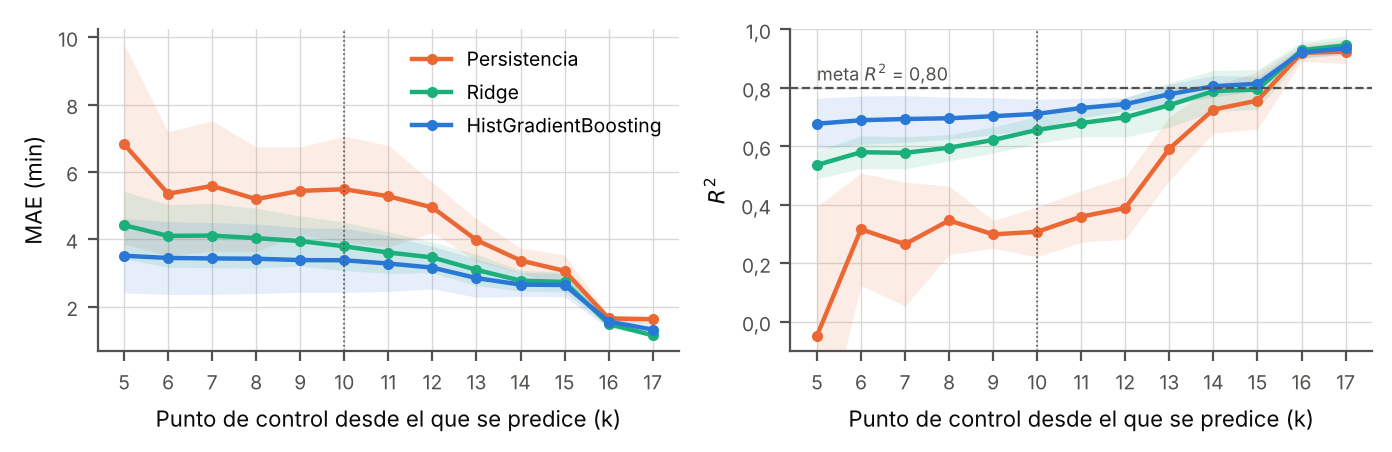


A. Curva por k (CV):
                         MAE                                       R2  \
modelo HistGradientBoosting Persistencia  Ridge HistGradientBoosting   
k                                                                      
5                     3.509        6.824  4.419                0.677   
6                     3.444        5.351  4.099                0.689   
7                     3.430        5.584  4.109                0.694   
8                     3.422        5.190  4.033                0.696   
9                     3.381        5.438  3.945                0.703   
10                    3.375        5.485  3.790                0.711   
11                    3.278        5.276  3.605                0.731   
12                    3.158        4.944  3.459                0.744   
13                    2.846        3.975  3.091                0.779   
14                    2.653        3.369  2.771                0.806   
15                    2.640        3.061 

difference_time == trunc(real - programada): 100.0000% de las celdas observadas
                                             regla unidad  afectados  total  porcentaje                                  tratamiento
               Paso no registrado ('-' / 00:00:00)  celda       7746  84726        9.14 NaN + indicador; nunca se imputa el objetivo
                   Horario programado no creciente vuelta        148   4707        3.14                               excluir vuelta
         Paso con hora incompatible (|d| > 30 min)  celda        249  84726        0.29                              marcar como NaN
Tiempo de tramo negativo (antes de R2: 30 vueltas) vuelta          0   4707        0.00                               excluir vuelta
                         Salto de retraso > 15 min vuelta         38   4707        0.81                      conservar con indicador
                               Vueltas conservadas vuelta       4559   4707       96.86                                   


B. Sensibilidad del umbral:
  umbral_min  vueltas_desarrollo  celdas_marcadas_NaN  MAE_cv_vueltas_comunes  MAE_cv_sd
         60                3082                  156                   3.212      0.794
         30                3066                  249                   3.196      0.739


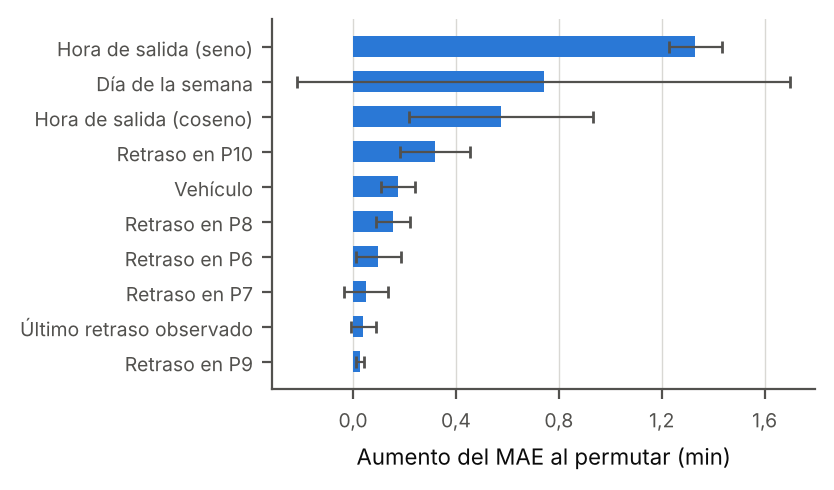


C. Importancia por permutación (top 10):
       variable  aumento_MAE  sd_pliegues
      hora_sin        1.331        0.104
    dia_semana        0.741        0.959
      hora_cos        0.576        0.357
           d10        0.319        0.136
      vehiculo        0.174        0.067
            d8        0.157        0.066
            d6        0.099        0.087
            d7        0.049        0.086
ultimo_retraso        0.039        0.049
            d9        0.027        0.017


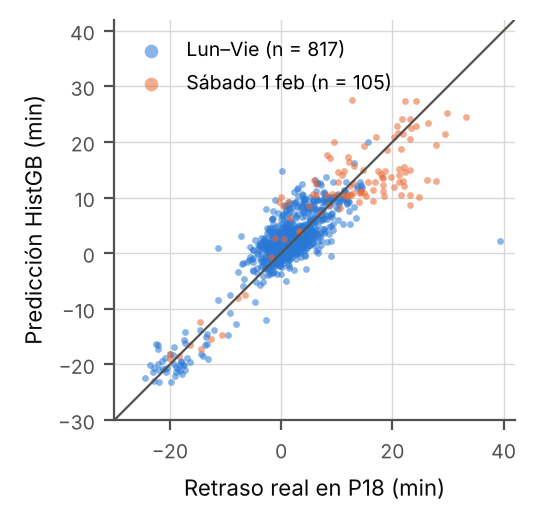


D. Prueba por plantilla (predicciones ya guardadas):
              n  MAE_HistGB  MAE_persistencia  retraso_mediano  \
plantilla                                                       
147         94        2.54              5.42           -14.23   
161        650        2.64              3.99             1.58   
168        178        3.37              4.90             4.66   

           vista_en_desarrollo  
plantilla                       
147                       True  
161                       True  
168                      False  


In [11]:
analisis()

## 6. Análisis de la revisión (sin reentrenar los modelos congelados)

- **A.** Comparación entre modelos tomando el día como unidad: *bootstrap* pareado y prueba de signo.
- **B.** Descomposición del error por subgrupo.
- **C.** Sesgo de selección: vueltas sin P18.
- **D.** Verificación de los pasos con $|d| > 60$.
- **E.** Datos de apoyo y tiempos.
- **F.** Línea base por hora y tipo de día, añadida después de la evaluación única.
- **G.** Corrección de Holm y $R^2$ por subgrupo.
- **H.** Sensibilidad a la semilla.

In [12]:
MODELOS = ["Retraso cero", "Persistencia", "Media histórica por hora", "Ridge", "Random Forest",
           "HistGradientBoosting"]
MEJOR = "HistGradientBoosting"


def a_min(hhmmss):
    h, m, s = (int(x) for x in hhmmss.split(":"))
    return h * 60 + m + s / 60


# ------------------------------------------------------------------ A
def comparacion_por_dia(p, rng, n_boot=5000):
    err = p[MODELOS].sub(p.real, axis=0).abs()
    mae_dia = err.groupby(p.fecha).mean()
    dias = mae_dia.index.to_numpy()
    idx = {d: np.flatnonzero(p.fecha.to_numpy() == d) for d in dias}
    filas = []
    for m in MODELOS:
        if m == MEJOR:
            continue
        dif = err[m] - err[MEJOR]  # > 0: el mejor modelo tiene menos error
        boots = []
        for _ in range(n_boot):
            sel = np.concatenate([idx[d] for d in rng.choice(dias, len(dias), replace=True)])
            boots.append(dif.iloc[sel].mean())
        gana = int((mae_dia[m] > mae_dia[MEJOR]).sum())
        filas.append({"modelo": m, "dif_MAE": dif.mean(),
                      "ic_inf": np.quantile(boots, 0.025), "ic_sup": np.quantile(boots, 0.975),
                      "dias_gana_HistGB": gana, "dias": len(dias),
                      "p_signo_bilateral": binomtest(gana, len(dias), 0.5).pvalue})
    t = pd.DataFrame(filas)
    t.round(4).to_csv(RES / "prueba_comparacion_por_dia.csv", index=False)
    return t


# ------------------------------------------------------------------ B
def descomposicion(p, df):
    p = p.merge(df[["id", "s1", "s18"]], on="id", validate="one_to_one")
    p["grupo"] = np.select(
        [pd.to_datetime(p.fecha).dt.dayofweek == 5, (p.s18 - p.s1).round() == 168],
        ["Sábado 1 feb", "Plantilla 168 (lun-vie)"], "Resto (lun-vie)")
    p["err"] = (p[MEJOR] - p.real).abs()
    total = p.err.sum()
    t = p.groupby("grupo").agg(vueltas=("err", "size"), MAE=("err", "mean"), suma=("err", "sum"))
    t["pct_vueltas"] = 100 * t.vueltas / len(p)
    t["pct_error_total"] = 100 * t.suma / total
    t = t.drop(columns="suma")
    t.round(3).to_csv(RES / "prueba_descomposicion_error.csv")
    return t


# ------------------------------------------------------------------ C
def sesgo_seleccion(dev_todo):
    g = dev_todo.assign(con_p18=dev_todo[OBJETIVO].notna(),
                        sabado=pd.to_datetime(dev_todo.fecha).dt.dayofweek == 5,
                        hora=dev_todo.s1 // 60)
    t = g.groupby("con_p18").agg(
        vueltas=("id", "size"), pct_sabado=("sabado", "mean"), hora_media=("hora", "mean"),
        d10_mediana=("d10", "median"), d14_mediana=("d14", "median"), d16_mediana=("d16", "median"),
        d14_p75=("d14", lambda s: s.quantile(.75)), d16_p75=("d16", lambda s: s.quantile(.75)))
    t["pct_sabado"] *= 100
    t.round(2).to_csv(RES / "sesgo_seleccion_p18.csv")
    return t


# ------------------------------------------------------------------ D
def pasos_anomalos(rng):
    T = pd.read_csv(DATASET, dtype={"vehicle_id_id": str})
    sep = lambda s: s.strip("{}").split(",")
    filas = []
    for r in T.itertuples():
        S = [a_min(x) for x in sep(r.start_time)]
        if any(b < a for a, b in zip(S, S[1:])):
            continue  # horario corrupto (se excluye en 01)
        dia = (pd.Timestamp(r.date) - pd.Timestamp("2025-01-01")).days
        for k, (s, e) in enumerate(zip(S, sep(r.end_time))):
            if e != "00:00:00":
                filas.append((r.id, r.vehicle_id_id, dia, k + 1, a_min(e), a_min(e) - s, S[0]))
    C = pd.DataFrame(filas, columns=["id", "veh", "dia", "punto", "real", "d", "salida"])
    C["t_abs"] = C.dia * 1440 + C.real
    validos = C[C.d.abs() <= 60]
    por_veh = {v: g for v, g in validos.groupby("veh")}

    def distancia(fila, desplazamiento):
        o = por_veh[fila.veh]
        o = o[o.id != fila.id]
        t = fila.dia * 1440 + fila.real + desplazamiento
        return (o.t_abs - t).abs().min()

    anom = C[C.d.abs() > 60]
    # Distancia mínima a un paso válido de otra vuelta del mismo bus (mismo día o siguiente).
    dist = [min(distancia(f, 0), distancia(f, 1440)) for f in anom.itertuples()]
    ref = []
    for f in validos.sample(300, random_state=SEMILLA).itertuples():
        sh = rng.uniform(-600, 600)
        ref.append(min(distancia(f, sh), distancia(f, sh + 1440)))
    neg = anom[anom.d < 0]
    res = {
        "celdas": len(anom), "negativas": int((anom.d < 0).sum()), "positivas": int((anom.d > 0).sum()),
        "negativas_hora_reloj_4a6": int(((neg.real >= 240) & (neg.real < 420)).sum()),
        "negativas_salida_16a20": int(((neg.salida >= 960) & (neg.salida < 1260)).sum()),
        "pct_a_2min_de_otro_paso": 100 * np.mean(np.array(dist) <= 2),
        "pct_a_2min_referencia_azar": 100 * np.mean(np.array(ref) <= 2),
        "puntos_mas_frecuentes": anom.punto.value_counts().head(5).to_dict(),
    }
    (RES / "pasos_anomalos.json").write_text(json.dumps(res, indent=2, ensure_ascii=False, default=int))
    return res


# ------------------------------------------------------------------ E
def apoyo(dev):
    X = construir(dev, K, vuelta_anterior=False)
    y = dev[OBJETIVO]
    conf = json.loads((RES / "configuracion.json").read_text())
    hgb = modelos(X.columns)[0]["HistGradientBoosting"].set_params(
        **conf["hiperparametros"]["HistGradientBoosting"])
    t0 = time.perf_counter()
    f = clone(hgb).fit(X, y)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    for _ in range(20):
        f.predict(X)
    t_pred = (time.perf_counter() - t0) / 20 / len(X)
    hora = (dev.s1 // 60).value_counts()
    veh = dev.vehiculo.value_counts()
    abl = pd.read_csv(RES / "ablacion_vuelta_anterior.csv")
    defecto = abl[~abl.vuelta_anterior].set_index("modelo").MAE_cv
    ajustado = pd.read_csv(RES / "cv_resultados.csv").set_index("modelo").MAE_media
    res = {
        "vueltas_por_hora_min": int(hora.min()), "horas_con_menos_de_30": int((hora < 30).sum()),
        "vueltas_por_vehiculo_min": int(veh.min()), "vueltas_por_vehiculo_mediana": float(veh.median()),
        "vueltas_por_vehiculo_max": int(veh.max()), "vehiculos": int(veh.size),
        "mae_cv_defecto": defecto.round(3).to_dict(),
        "mae_cv_ajustado": ajustado.loc[defecto.index].round(3).to_dict(),
        "entrenamiento_HistGB_s": round(t_fit, 2), "inferencia_ms_por_vuelta": round(1000 * t_pred, 4),
    }
    (RES / "apoyo_revision.json").write_text(json.dumps(res, indent=2, ensure_ascii=False))
    return res


# ------------------------------------------------------------------ F
class MediaHoraTipoDia(BaseEstimator, RegressorMixin):
    """Media del retraso en P18 por hora de salida y tipo de día (lun-vie, sáb, dom).

    Si una celda tiene menos de MIN_CELDA vueltas de entrenamiento, usa la media por hora;
    si tampoco hay, la media global.
    """
    MIN_CELDA = 5

    def fit(self, X, y):
        h, t = self._claves(X)
        y = pd.Series(np.asarray(y))
        g = y.groupby([h, t]).agg(["mean", "size"])
        self.celda_ = g.loc[g["size"] >= self.MIN_CELDA, "mean"]
        self.hora_ = y.groupby(h).mean()
        self.global_ = float(y.mean())
        return self

    def predict(self, X):
        h, t = self._claves(X)
        celda = pd.Series(list(zip(h, t))).map(self.celda_.to_dict())
        return celda.fillna(pd.Series(h).map(self.hora_)).fillna(self.global_).to_numpy()

    @staticmethod
    def _claves(X):
        h = MediaHistoricaHora._hora(X).to_numpy()
        d = X["dia_semana"].to_numpy()
        return h, np.where(d == 5, 1, np.where(d == 6, 2, 0))


def linea_base_tipo_dia(dev, test):
    X_dev = construir(dev, K, vuelta_anterior=False)
    pl = pliegues_forward_chaining(dev.fecha)
    cv = cv_por_pliegue(MediaHoraTipoDia(), X_dev, dev[OBJETIVO], pl)
    X_te = construir(test, K, vuelta_anterior=False)
    p = MediaHoraTipoDia().fit(X_dev, dev[OBJETIVO]).predict(X_te)
    m = metricas(test[OBJETIVO], p)
    res = {"MAE_cv": cv.MAE.mean(), "MAE_cv_sd": cv.MAE.std(), "R2_cv": cv.R2.mean(),
           **{f"{k}_prueba": v for k, v in m.items()}}
    pd.Series(res).round(4).to_csv(RES / "linea_base_hora_tipo_dia.csv", header=["valor"])
    return res, pd.Series(p, index=test.index)


# ------------------------------------------------------------------ G
def holm_y_subgrupos(p, df, rng, n_boot=5000):
    err = p[MODELOS].sub(p.real, axis=0).abs()
    dias = p.fecha.unique()
    idx = {d: np.flatnonzero(p.fecha.to_numpy() == d) for d in dias}
    filas = []
    for m in [x for x in MODELOS if x != MEJOR]:
        dif = (err[m] - err[MEJOR]).to_numpy()
        b = np.array([dif[np.concatenate([idx[d] for d in rng.choice(dias, len(dias))])].mean()
                      for _ in range(n_boot)])
        # p bilateral por bootstrap (inversión del IC percentil).
        pv = min(1.0, 2 * min((b <= 0).mean(), (b >= 0).mean()))
        filas.append({"modelo": m, "dif_MAE": dif.mean(), "p_bootstrap": max(pv, 1 / n_boot)})
    t = pd.DataFrame(filas).sort_values("p_bootstrap").reset_index(drop=True)
    k = len(t)
    t["p_holm"] = np.maximum.accumulate([min(1, (k - i) * v) for i, v in enumerate(t.p_bootstrap)])
    t.round(4).to_csv(RES / "prueba_holm.csv", index=False)

    q = p.merge(df[["id", "s1", "s18"]], on="id", validate="one_to_one")
    q["grupo"] = np.select(
        [pd.to_datetime(q.fecha).dt.dayofweek == 5, (q.s18 - q.s1).round() == 168],
        ["Sábado 1 feb", "Plantilla 168 (lun-vie)"], "Resto (lun-vie)")
    filas = []
    for g, s in list(q.groupby("grupo")) + [("Total", q)]:
        filas.append({"grupo": g, "vueltas": len(s), "sd_real": s.real.std(),
                      "MAE": (s[MEJOR] - s.real).abs().mean(), "R2": r2_score(s.real, s[MEJOR])})
    for f, s in q.groupby("fecha"):
        filas.append({"grupo": f, "vueltas": len(s), "sd_real": s.real.std(),
                      "MAE": (s[MEJOR] - s.real).abs().mean(), "R2": r2_score(s.real, s[MEJOR])})
    sub = pd.DataFrame(filas)
    sub.round(3).to_csv(RES / "prueba_r2_subgrupos.csv", index=False)
    return t, sub


# ------------------------------------------------------------------ H
def semillas(dev):
    X = construir(dev, K, vuelta_anterior=False)
    y = dev[OBJETIVO]
    pl = pliegues_forward_chaining(dev.fecha)
    mods, esp = modelos(X.columns)
    filas = []
    for sem in [0, 1, 2, 42]:
        b = RandomizedSearchCV(mods["HistGradientBoosting"], esp["HistGradientBoosting"], n_iter=N_ITER,
                               cv=pl, scoring="neg_mean_absolute_error", random_state=sem, n_jobs=-1,
                               refit=False).fit(X, y)
        filas.append({"experimento": "búsqueda HistGB", "semilla": sem, "MAE_cv": -b.best_score_})
    conf = json.loads((RES / "configuracion.json").read_text())
    for sem in [0, 1, 2, 3, 42]:
        rf = clone(mods["Random Forest"]).set_params(**conf["hiperparametros"]["Random Forest"],
                                                     randomforestregressor__random_state=sem)
        filas.append({"experimento": "semilla Random Forest", "semilla": sem,
                      "MAE_cv": cv_por_pliegue(rf, X, y, pl).MAE.mean()})
    t = pd.DataFrame(filas)
    t.round(4).to_csv(RES / "sensibilidad_semilla.csv", index=False)
    return t


def revision():
    rng = np.random.default_rng(SEMILLA)
    df = pd.read_csv(RAIZ / "data/vueltas_limpias.csv", dtype={"vehiculo": str})
    p = pd.read_csv(RES / "prueba_predicciones.csv")
    print("A. Diferencia de MAE frente a HistGB (unidad: día):\n",
          comparacion_por_dia(p, rng).round(3).to_string(index=False))
    print("\nB. Descomposición del error de prueba:\n", descomposicion(p, df).round(2))
    dev_todo = df[df.fecha <= FIN_DESARROLLO]
    print("\nC. Sesgo de selección (desarrollo):\n", sesgo_seleccion(dev_todo).round(2).T)
    print("\nD. Pasos con |d| > 60:\n", pasos_anomalos(rng))
    dev = dev_todo[dev_todo[OBJETIVO].notna()].reset_index(drop=True)
    print("\nE. Apoyo:\n", json.dumps(apoyo(dev), indent=1, ensure_ascii=False))
    test = df[(df.fecha >= INICIO_PRUEBA) & df[OBJETIVO].notna()].reset_index(drop=True)
    lb, pred_lb = linea_base_tipo_dia(dev, test)
    print("\nF. Línea base hora x tipo de día:\n", {k: round(v, 3) for k, v in lb.items()})
    assert (p.id.to_numpy() == test.id.to_numpy()).all()
    dif = ((pred_lb - test[OBJETIVO]).abs() - (p[MEJOR] - p.real).abs()).to_numpy()
    dias = p.fecha.unique()
    idx = {d: np.flatnonzero(p.fecha.to_numpy() == d) for d in dias}
    b = [dif[np.concatenate([idx[d] for d in rng.choice(dias, len(dias))])].mean() for _ in range(5000)]
    gana = int((pd.Series(dif).groupby(p.fecha.to_numpy()).mean() > 0).sum())
    pd.DataFrame([{"dif_MAE": dif.mean(), "ic_inf": np.quantile(b, .025), "ic_sup": np.quantile(b, .975),
                   "dias_gana_HistGB": gana}]).round(4).to_csv(RES / "linea_base_hora_tipo_dia_vs_histgb.csv", index=False)
    print(f"   vs HistGB: +{dif.mean():.3f} [{np.quantile(b, .025):.3f}; {np.quantile(b, .975):.3f}], gana HistGB {gana}/6 días")
    holm, sub = holm_y_subgrupos(p, df, rng)
    print("\nG. Holm:\n", holm.round(4).to_string(index=False), "\n", sub.round(3).to_string(index=False))
    print("\nH. Semillas:\n", semillas(dev).round(3).to_string(index=False))


In [13]:
revision()

A. Diferencia de MAE frente a HistGB (unidad: día):
                   modelo  dif_MAE  ic_inf  ic_sup  dias_gana_HistGB  dias  p_signo_bilateral
            Retraso cero    2.844   1.712   5.316                 6     6              0.031
            Persistencia    1.545   0.942   2.831                 6     6              0.031
Media histórica por hora    1.665   0.916   2.991                 6     6              0.031
                   Ridge    0.639   0.349   0.899                 6     6              0.031
           Random Forest    0.200   0.023   0.370                 5     6              0.219

B. Descomposición del error de prueba:
                          vueltas   MAE  pct_vueltas  pct_error_total
grupo                                                               
Plantilla 168 (lun-vie)      178  3.37        19.31            23.51
Resto (lun-vie)              639  2.30        69.31            57.55
Sábado 1 feb                 105  4.61        11.39            18.94

C.


D. Pasos con |d| > 60:
 {'celdas': 156, 'negativas': 141, 'positivas': 15, 'negativas_hora_reloj_4a6': 122, 'negativas_salida_16a20': 126, 'pct_a_2min_de_otro_paso': np.float64(13.461538461538462), 'pct_a_2min_referencia_azar': np.float64(32.666666666666664), 'puntos_mas_frecuentes': {18: 46, 16: 30, 11: 19, 17: 17, 15: 15}}



E. Apoyo:
 {
 "vueltas_por_hora_min": 1,
 "horas_con_menos_de_30": 1,
 "vueltas_por_vehiculo_min": 39,
 "vueltas_por_vehiculo_mediana": 70.0,
 "vueltas_por_vehiculo_max": 91,
 "vehiculos": 45,
 "mae_cv_defecto": {
  "Ridge": 3.789,
  "Random Forest": 3.566,
  "HistGradientBoosting": 3.484
 },
 "mae_cv_ajustado": {
  "Ridge": 3.79,
  "Random Forest": 3.533,
  "HistGradientBoosting": 3.375
 },
 "entrenamiento_HistGB_s": 0.34,
 "inferencia_ms_por_vuelta": 0.0095
}

F. Línea base hora x tipo de día:
 {'MAE_cv': np.float64(3.995), 'MAE_cv_sd': np.float64(1.01), 'R2_cv': np.float64(0.584), 'MAE_prueba': np.float64(3.335), 'RMSE_prueba': np.float64(4.761), 'R2_prueba': 0.665, 'pct_err_le_2_prueba': np.float64(43.384)}
   vs HistGB: +0.565 [0.346; 0.804], gana HistGB 6/6 días



G. Holm:
                   modelo  dif_MAE  p_bootstrap  p_holm
            Retraso cero   2.8438       0.0002  0.0010
            Persistencia   1.5454       0.0002  0.0010
Media histórica por hora   1.6655       0.0002  0.0010
                   Ridge   0.6388       0.0002  0.0010
           Random Forest   0.1998       0.0196  0.0196 
                   grupo  vueltas  sd_real   MAE    R2
Plantilla 168 (lun-vie)      178    5.143 3.373 0.298
        Resto (lun-vie)      639    6.739 2.301 0.722
           Sábado 1 feb      105   11.537 4.607 0.734
                  Total      922    8.234 2.770 0.760
             2025-01-27      164    6.759 3.140 0.642
             2025-01-28      149    6.673 2.104 0.829
             2025-01-29      163    6.051 2.398 0.743
             2025-01-30      174    5.881 2.125 0.778
             2025-01-31      167    7.709 2.883 0.524
             2025-02-01      105   11.537 4.607 0.734



H. Semillas:
           experimento  semilla  MAE_cv
      búsqueda HistGB        0   3.381
      búsqueda HistGB        1   3.381
      búsqueda HistGB        2   3.386
      búsqueda HistGB       42   3.375
semilla Random Forest        0   3.540
semilla Random Forest        1   3.553
semilla Random Forest        2   3.540
semilla Random Forest        3   3.526
semilla Random Forest       42   3.533


## 7. Comprobación: ¿coincide con la evaluación oficial?
Compara la tabla de prueba de este notebook con la del repositorio (`../resultados/prueba_resultados.csv`), generada con el protocolo congelado.

In [14]:
oficial = CARPETA.parent / "resultados" / "prueba_resultados.csv"
nuevo = pd.read_csv(RES / "prueba_resultados.csv")
cols = ["modelo", "MAE", "RMSE", "R2", "pct_err_le_2"]
if oficial.exists():
    ref = pd.read_csv(oficial)
    dif = (nuevo[cols[1:]] - ref[cols[1:]]).abs().to_numpy().max()
    print(f"Diferencia máxima con la evaluación oficial: {dif:.6f}")
    assert dif < 1e-3, "Los resultados no coinciden con la evaluación oficial"
    print("OK: el notebook reproduce la evaluación oficial.")
else:
    print("No se encontró la tabla oficial (fuera del repositorio); resultados de este notebook:")
nuevo[cols].round(3)

Diferencia máxima con la evaluación oficial: 0.000000
OK: el notebook reproduce la evaluación oficial.


,modelo,MAE,RMSE,R2,pct_err_le_2
0,Retraso cero,5.614,8.510,-0.069,36.334
1,Persistencia,4.316,6.147,0.442,35.792
2,Media histórica por hora,4.436,6.171,0.438,33.731
3,Ridge,3.409,4.609,0.686,37.852
4,Random Forest,2.970,4.322,0.724,47.939
5,HistGradientBoosting,2.770,4.035,0.760,49.349
